# Project INTRODUCTION TO DATA SCIENCE

In [ ]:
import pandas as pd
import numpy as np
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix as cm
from sklearn.metrics import ConfusionMatrixDisplay as cmd
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn import tree
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score as cvscore
from sklearn.metrics import roc_auc_score
from pathlib import Path
from preprocessing import prepare_train_test_data, resample_training_data


In [ ]:
data_path = Path("content") / "creditcard.csv"
if not data_path.is_file():
    raise FileNotFoundError(
        f"Dataset not found at {data_path}. Download creditcard.csv and place it there."
    )
df = pd.read_csv(data_path)


In [ ]:
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
df.isnull().any().any()

False

In [ ]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [ ]:
df[df.duplicated()]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
282987,171288.0,1.912550,-0.455240,-1.750654,0.454324,2.089130,4.160019,-0.881302,1.081750,1.022928,...,-0.524067,-1.337510,0.473943,0.616683,-0.283548,-1.084843,0.073133,-0.036020,11.99,0
283483,171627.0,-1.464380,1.368119,0.815992,-0.601282,-0.689115,-0.487154,-0.303778,0.884953,0.054065,...,0.287217,0.947825,-0.218773,0.082926,0.044127,0.639270,0.213565,0.119251,6.82,0
283485,171627.0,-1.457978,1.378203,0.811515,-0.603760,-0.711883,-0.471672,-0.282535,0.880654,0.052808,...,0.284205,0.949659,-0.216949,0.083250,0.044944,0.639933,0.219432,0.116772,11.93,0
284191,172233.0,-2.667936,3.160505,-3.355984,1.007845,-0.377397,-0.109730,-0.667233,2.309700,-1.639306,...,0.391483,0.266536,-0.079853,-0.096395,0.086719,-0.451128,-1.183743,-0.222200,55.66,0


In [ ]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283721,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
283722,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
283723,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
283724,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [ ]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


# Exploratory Data Analysis

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

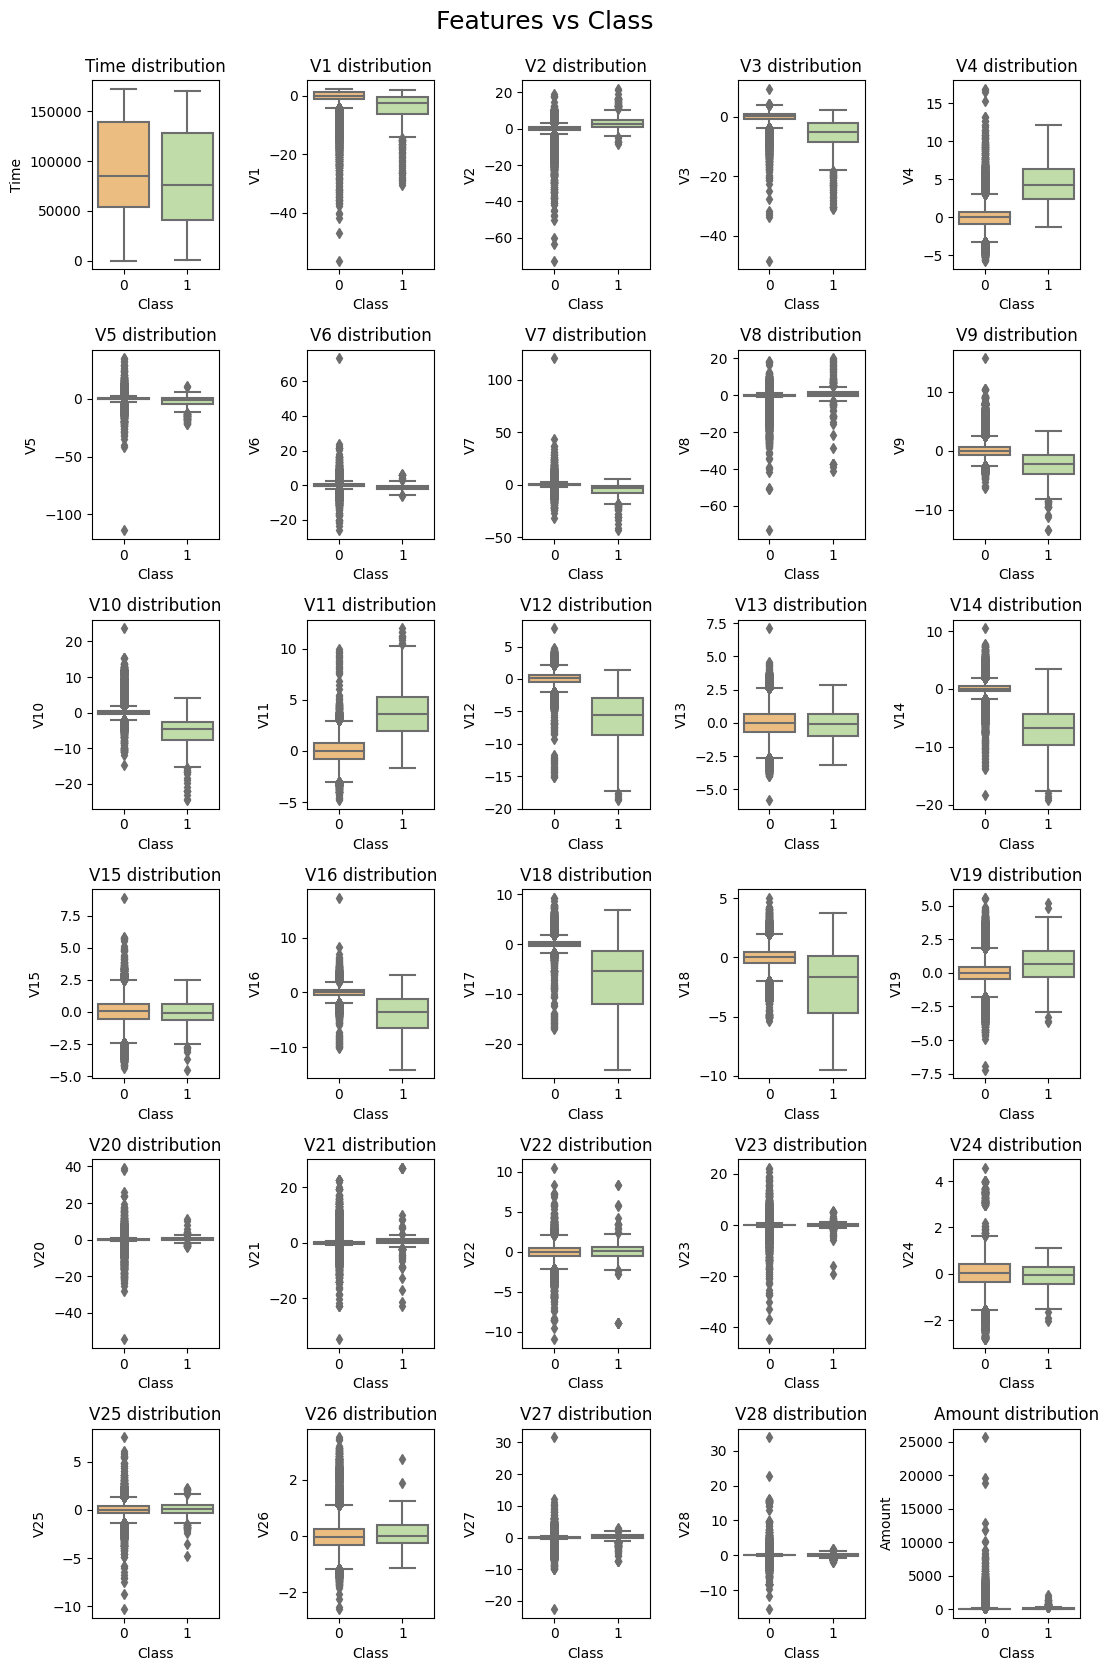

In [ ]:
fig, axes = plt.subplots(nrows=6, ncols=5,figsize=(11,17))
fig.suptitle('Features vs Class\n', size = 18)

sns.boxplot(ax=axes[0, 0], df=df, x='Class', y='Time', palette='Spectral')
axes[0,0].set_title("Time distribution")

sns.boxplot(ax=axes[0, 1], df=df, x='Class', y='V1', palette='Spectral')
axes[0,1].set_title("V1 distribution")

sns.boxplot(ax=axes[0, 2], df=df, x='Class', y='V2', palette='Spectral')
axes[0,2].set_title("V2 distribution")

sns.boxplot(ax=axes[0, 3], df=df, x='Class', y='V3', palette='Spectral')
axes[0,3].set_title("V3 distribution")

sns.boxplot(ax=axes[0, 4], df=df, x='Class', y='V4', palette='Spectral')
axes[0,4].set_title("V4 distribution")

sns.boxplot(ax=axes[1, 0], df=df, x='Class', y='V5', palette='Spectral')
axes[1,0].set_title("V5 distribution")

sns.boxplot(ax=axes[1, 1], df=df, x='Class', y='V6', palette='Spectral')
axes[1,1].set_title("V6 distribution")

sns.boxplot(ax=axes[1, 2], df=df, x='Class', y='V7', palette='Spectral')
axes[1,2].set_title("V7 distribution")

sns.boxplot(ax=axes[1, 3], df=df, x='Class', y='V8', palette='Spectral')
axes[1,3].set_title("V8 distribution")

sns.boxplot(ax=axes[1, 4], df=df, x='Class', y='V9', palette='Spectral')
axes[1,4].set_title("V9 distribution")

sns.boxplot(ax=axes[2, 0], df=df, x='Class', y='V10', palette='Spectral')
axes[2,0].set_title("V10 distribution")

sns.boxplot(ax=axes[2, 1], df=df, x='Class', y='V11', palette='Spectral')
axes[2,1].set_title("V11 distribution")

sns.boxplot(ax=axes[2, 2], df=df, x='Class', y='V12', palette='Spectral')
axes[2,2].set_title("V12 distribution")

sns.boxplot(ax=axes[2, 3], df=df, x='Class', y='V13', palette='Spectral')
axes[2,3].set_title("V13 distribution")

sns.boxplot(ax=axes[2, 4], df=df, x='Class', y='V14', palette='Spectral')
axes[2,4].set_title("V14 distribution")

sns.boxplot(ax=axes[3, 0], df=df, x='Class', y='V15', palette='Spectral')
axes[3,0].set_title("V15 distribution")

sns.boxplot(ax=axes[3, 1], df=df, x='Class', y='V16', palette='Spectral')
axes[3,1].set_title("V16 distribution")

sns.boxplot(ax=axes[3, 2], df=df, x='Class', y='V17', palette='Spectral')
axes[3,2].set_title("V17 distribution")

sns.boxplot(ax=axes[3, 3], df=df, x='Class', y='V18', palette='Spectral')
axes[3,2].set_title("V18 distribution")

sns.boxplot(ax=axes[3, 4], df=df, x='Class', y='V19', palette='Spectral')
axes[3,4].set_title("V19 distribution")

sns.boxplot(ax=axes[4, 0], df=df, x='Class', y='V20', palette='Spectral')
axes[4,0].set_title("V20 distribution")

sns.boxplot(ax=axes[4, 1], df=df, x='Class', y='V21', palette='Spectral')
axes[4,1].set_title("V21 distribution")

sns.boxplot(ax=axes[4, 2], df=df, x='Class', y='V22', palette='Spectral')
axes[4,2].set_title("V22 distribution")

sns.boxplot(ax=axes[4, 3], df=df, x='Class', y='V23', palette='Spectral')
axes[4,3].set_title("V23 distribution")

sns.boxplot(ax=axes[4, 4], df=df, x='Class', y='V24', palette='Spectral')
axes[4,4].set_title("V24 distribution")

sns.boxplot(ax=axes[5, 0], df=df, x='Class', y='V25', palette='Spectral')
axes[5,0].set_title("V25 distribution")

sns.boxplot(ax=axes[5, 1], df=df, x='Class', y='V26', palette='Spectral')
axes[5,1].set_title("V26 distribution")

sns.boxplot(ax=axes[5, 2], df=df, x='Class', y='V27', palette='Spectral')
axes[5,2].set_title("V27 distribution")

sns.boxplot(ax=axes[5, 3], df=df, x='Class', y='V28', palette='Spectral')
axes[5,3].set_title("V28 distribution")

sns.boxplot(ax=axes[5, 4], df=df, x='Class', y='Amount', palette='Spectral')
axes[5,4].set_title("Amount distribution")

plt.tight_layout()
plt.show()

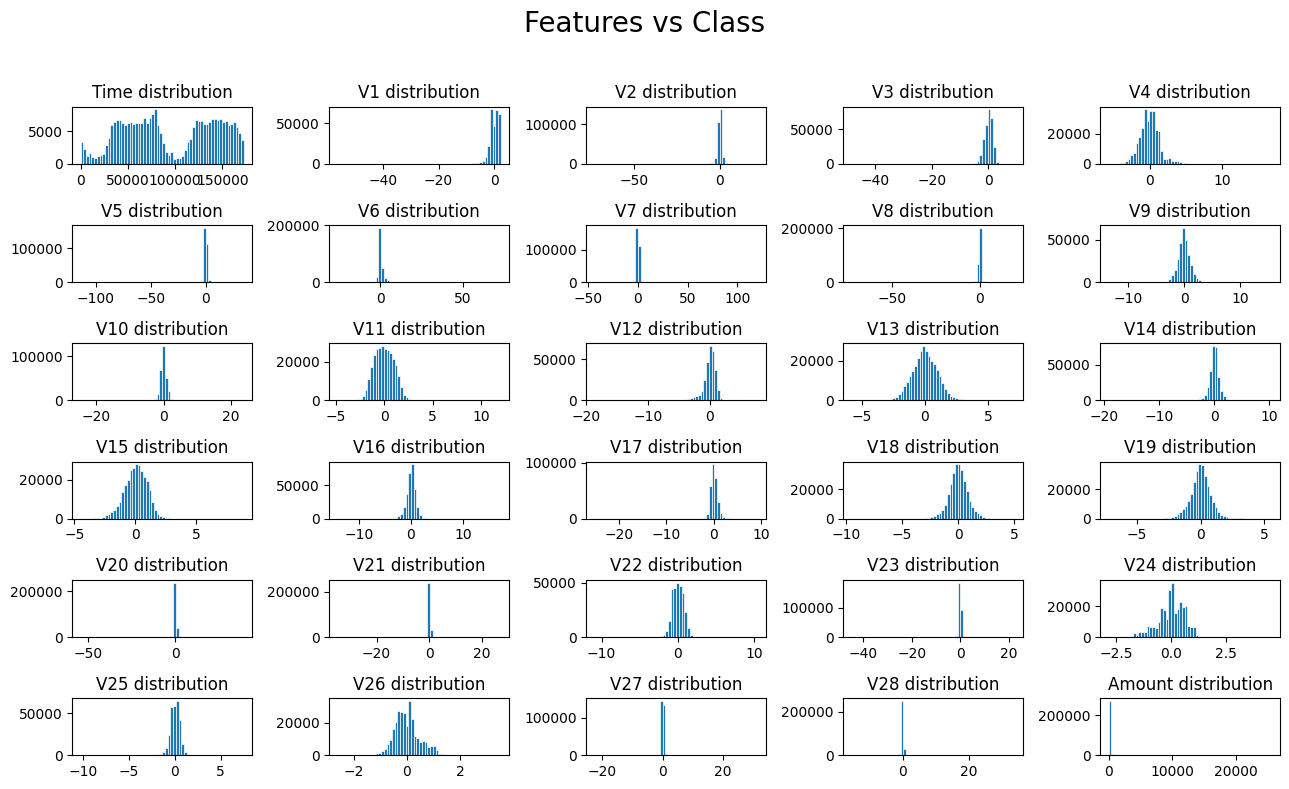

In [ ]:
fig, axes = plt.subplots(nrows=6, ncols=5,figsize=(13,8))
fig.suptitle('Features vs Class\n', size = 20)

axes[0,0].hist(df['Time'], bins=60, linewidth=0.5, edgecolor="white")
axes[0,0].set_title("Time distribution")

axes[0,1].hist(df['V1'], bins=60, linewidth=0.5, edgecolor="white")
axes[0,1].set_title("V1 distribution");

axes[0,2].hist(df['V2'], bins=60, linewidth=0.5, edgecolor="white")
axes[0,2].set_title("V2 distribution");

axes[0,3].hist(df['V3'], bins=60, linewidth=0.5, edgecolor="white")
axes[0,3].set_title("V3 distribution");

axes[0,4].hist(df['V4'], bins=60, linewidth=0.5, edgecolor="white")
axes[0,4].set_title("V4 distribution");

axes[1,0].hist(df['V5'], bins=60, linewidth=0.5, edgecolor="white")
axes[1,0].set_title("V5 distribution");

axes[1,1].hist(df['V6'], bins=60, linewidth=0.5, edgecolor="white")
axes[1,1].set_title("V6 distribution");

axes[1,2].hist(df['V7'], bins=60, linewidth=0.5, edgecolor="white")
axes[1,2].set_title("V7 distribution");

axes[1,3].hist(df['V8'], bins=60, linewidth=0.5, edgecolor="white")
axes[1,3].set_title("V8 distribution");

axes[1,4].hist(df['V9'], bins=60, linewidth=0.5, edgecolor="white")
axes[1,4].set_title("V9 distribution");

axes[2,0].hist(df['V10'], bins=60, linewidth=0.5, edgecolor="white")
axes[2,0].set_title("V10 distribution");

axes[2,1].hist(df['V11'], bins=60, linewidth=0.5, edgecolor="white")
axes[2,1].set_title("V11 distribution");

axes[2,2].hist(df['V12'], bins=60, linewidth=0.5, edgecolor="white")
axes[2,2].set_title("V12 distribution");

axes[2,3].hist(df['V13'], bins=60, linewidth=0.5, edgecolor="white")
axes[2,3].set_title("V13 distribution");

axes[2,4].hist(df['V14'], bins=60, linewidth=0.5, edgecolor="white")
axes[2,4].set_title("V14 distribution");

axes[3,0].hist(df['V15'], bins=60, linewidth=0.5, edgecolor="white")
axes[3,0].set_title("V15 distribution");

axes[3,1].hist(df['V16'], bins=60, linewidth=0.5, edgecolor="white")
axes[3,1].set_title("V16 distribution");

axes[3,2].hist(df['V17'], bins=60, linewidth=0.5, edgecolor="white")
axes[3,2].set_title("V17 distribution");

axes[3,3].hist(df['V18'], bins=60, linewidth=0.5, edgecolor="white")
axes[3,3].set_title("V18 distribution");

axes[3,4].hist(df['V19'], bins=60, linewidth=0.5, edgecolor="white")
axes[3,4].set_title("V19 distribution");

axes[4,0].hist(df['V20'], bins=60, linewidth=0.5, edgecolor="white")
axes[4,0].set_title("V20 distribution");

axes[4,1].hist(df['V21'], bins=60, linewidth=0.5, edgecolor="white")
axes[4,1].set_title("V21 distribution");

axes[4,2].hist(df['V22'], bins=60, linewidth=0.5, edgecolor="white")
axes[4,2].set_title("V22 distribution");

axes[4,3].hist(df['V23'], bins=60, linewidth=0.5, edgecolor="white")
axes[4,3].set_title("V23 distribution");

axes[4,4].hist(df['V24'], bins=60, linewidth=0.5, edgecolor="white")
axes[4,4].set_title("V24 distribution");

axes[5,0].hist(df['V25'], bins=60, linewidth=0.5, edgecolor="white")
axes[5,0].set_title("V25 distribution");

axes[5,1].hist(df['V26'], bins=60, linewidth=0.5, edgecolor="white")
axes[5,1].set_title("V26 distribution");

axes[5,2].hist(df['V27'], bins=60, linewidth=0.5, edgecolor="white")
axes[5,2].set_title("V27 distribution");

axes[5,3].hist(df['V28'], bins=60, linewidth=0.5, edgecolor="white")
axes[5,3].set_title("V28 distribution");

axes[5,4].hist(df['Amount'], bins=60, linewidth=0.5, edgecolor="white")
axes[5,4].set_title("Amount distribution");

plt.tight_layout()
plt.show()

Distribution of Amount for Fradulent & Genuine transactions

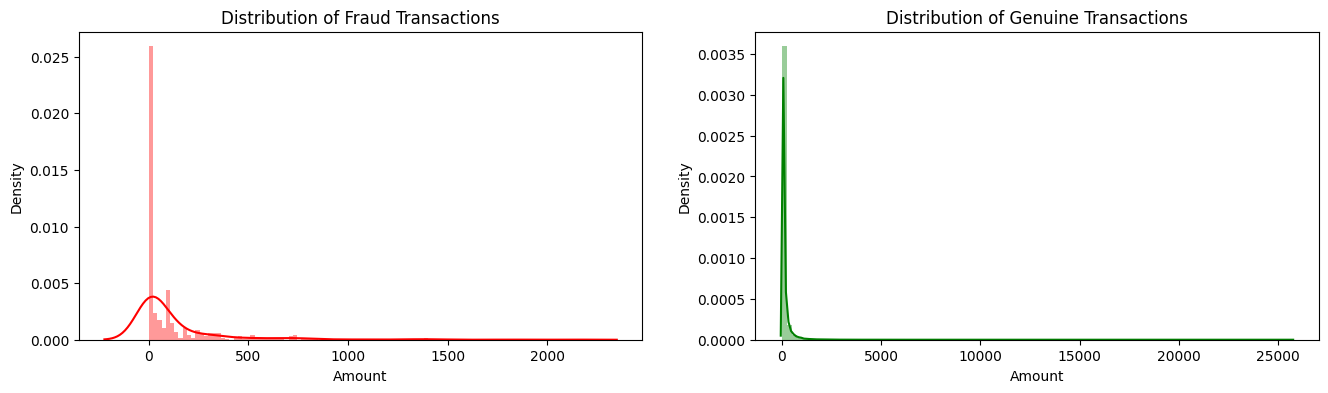

In [ ]:
fig, axs = plt.subplots(ncols=2,figsize=(16,4))
sns.distplot(df[df['Class'] == 1]['Amount'], bins=100, color='red', ax=axs[0])
axs[0].set_title("Distribution of Fraud Transactions")

sns.distplot(df[df['Class'] == 0]['Amount'], bins=100, color='green', ax=axs[1])
axs[1].set_title("Distribution of Genuine Transactions")

plt.show()

Distribution of Time for Fradulent & Genuine transactions

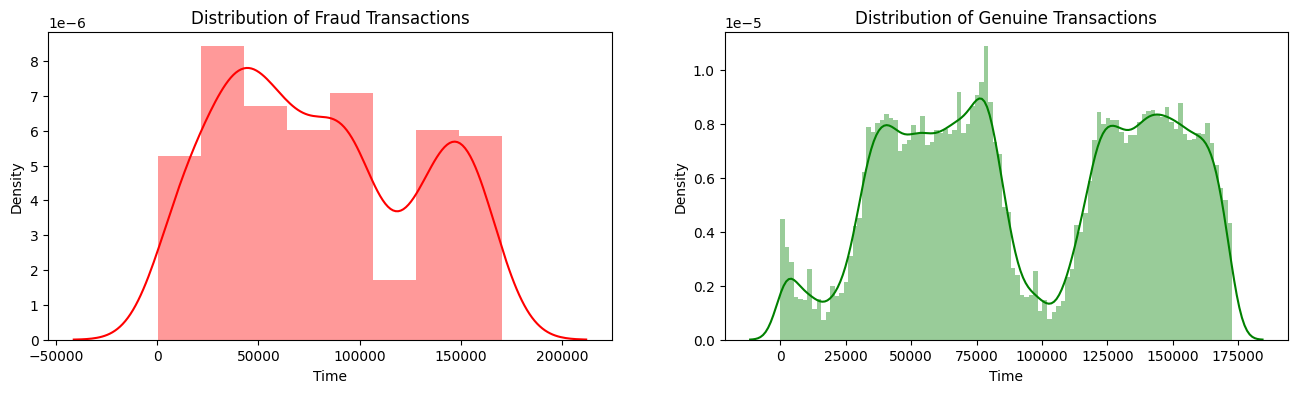

In [ ]:
fig, axs = plt.subplots(ncols=2,figsize=(16,4))
sns.distplot(df[df['Class'] == 1]['Time'], color='red', ax=axs[0])
axs[0].set_title("Distribution of Fraud Transactions")

sns.distplot(df[df['Class'] == 0]['Time'], bins=100, color='green', ax=axs[1])
axs[1].set_title("Distribution of Genuine Transactions")

plt.show()

In [ ]:
print("Fraud Transaction distribution : \n",df[(df['Class'] == 1)]['Amount'].value_counts().head())

Fraud Transaction distribution : 
 1.00     113
0.00      27
99.99     27
0.76      17
0.77      10
Name: Amount, dtype: int64


There are 113 fraud transactions for just one dollar and 27 fraud transaction for 99.99 dollars. There are also 27 transactions for zero amount

<Axes: >

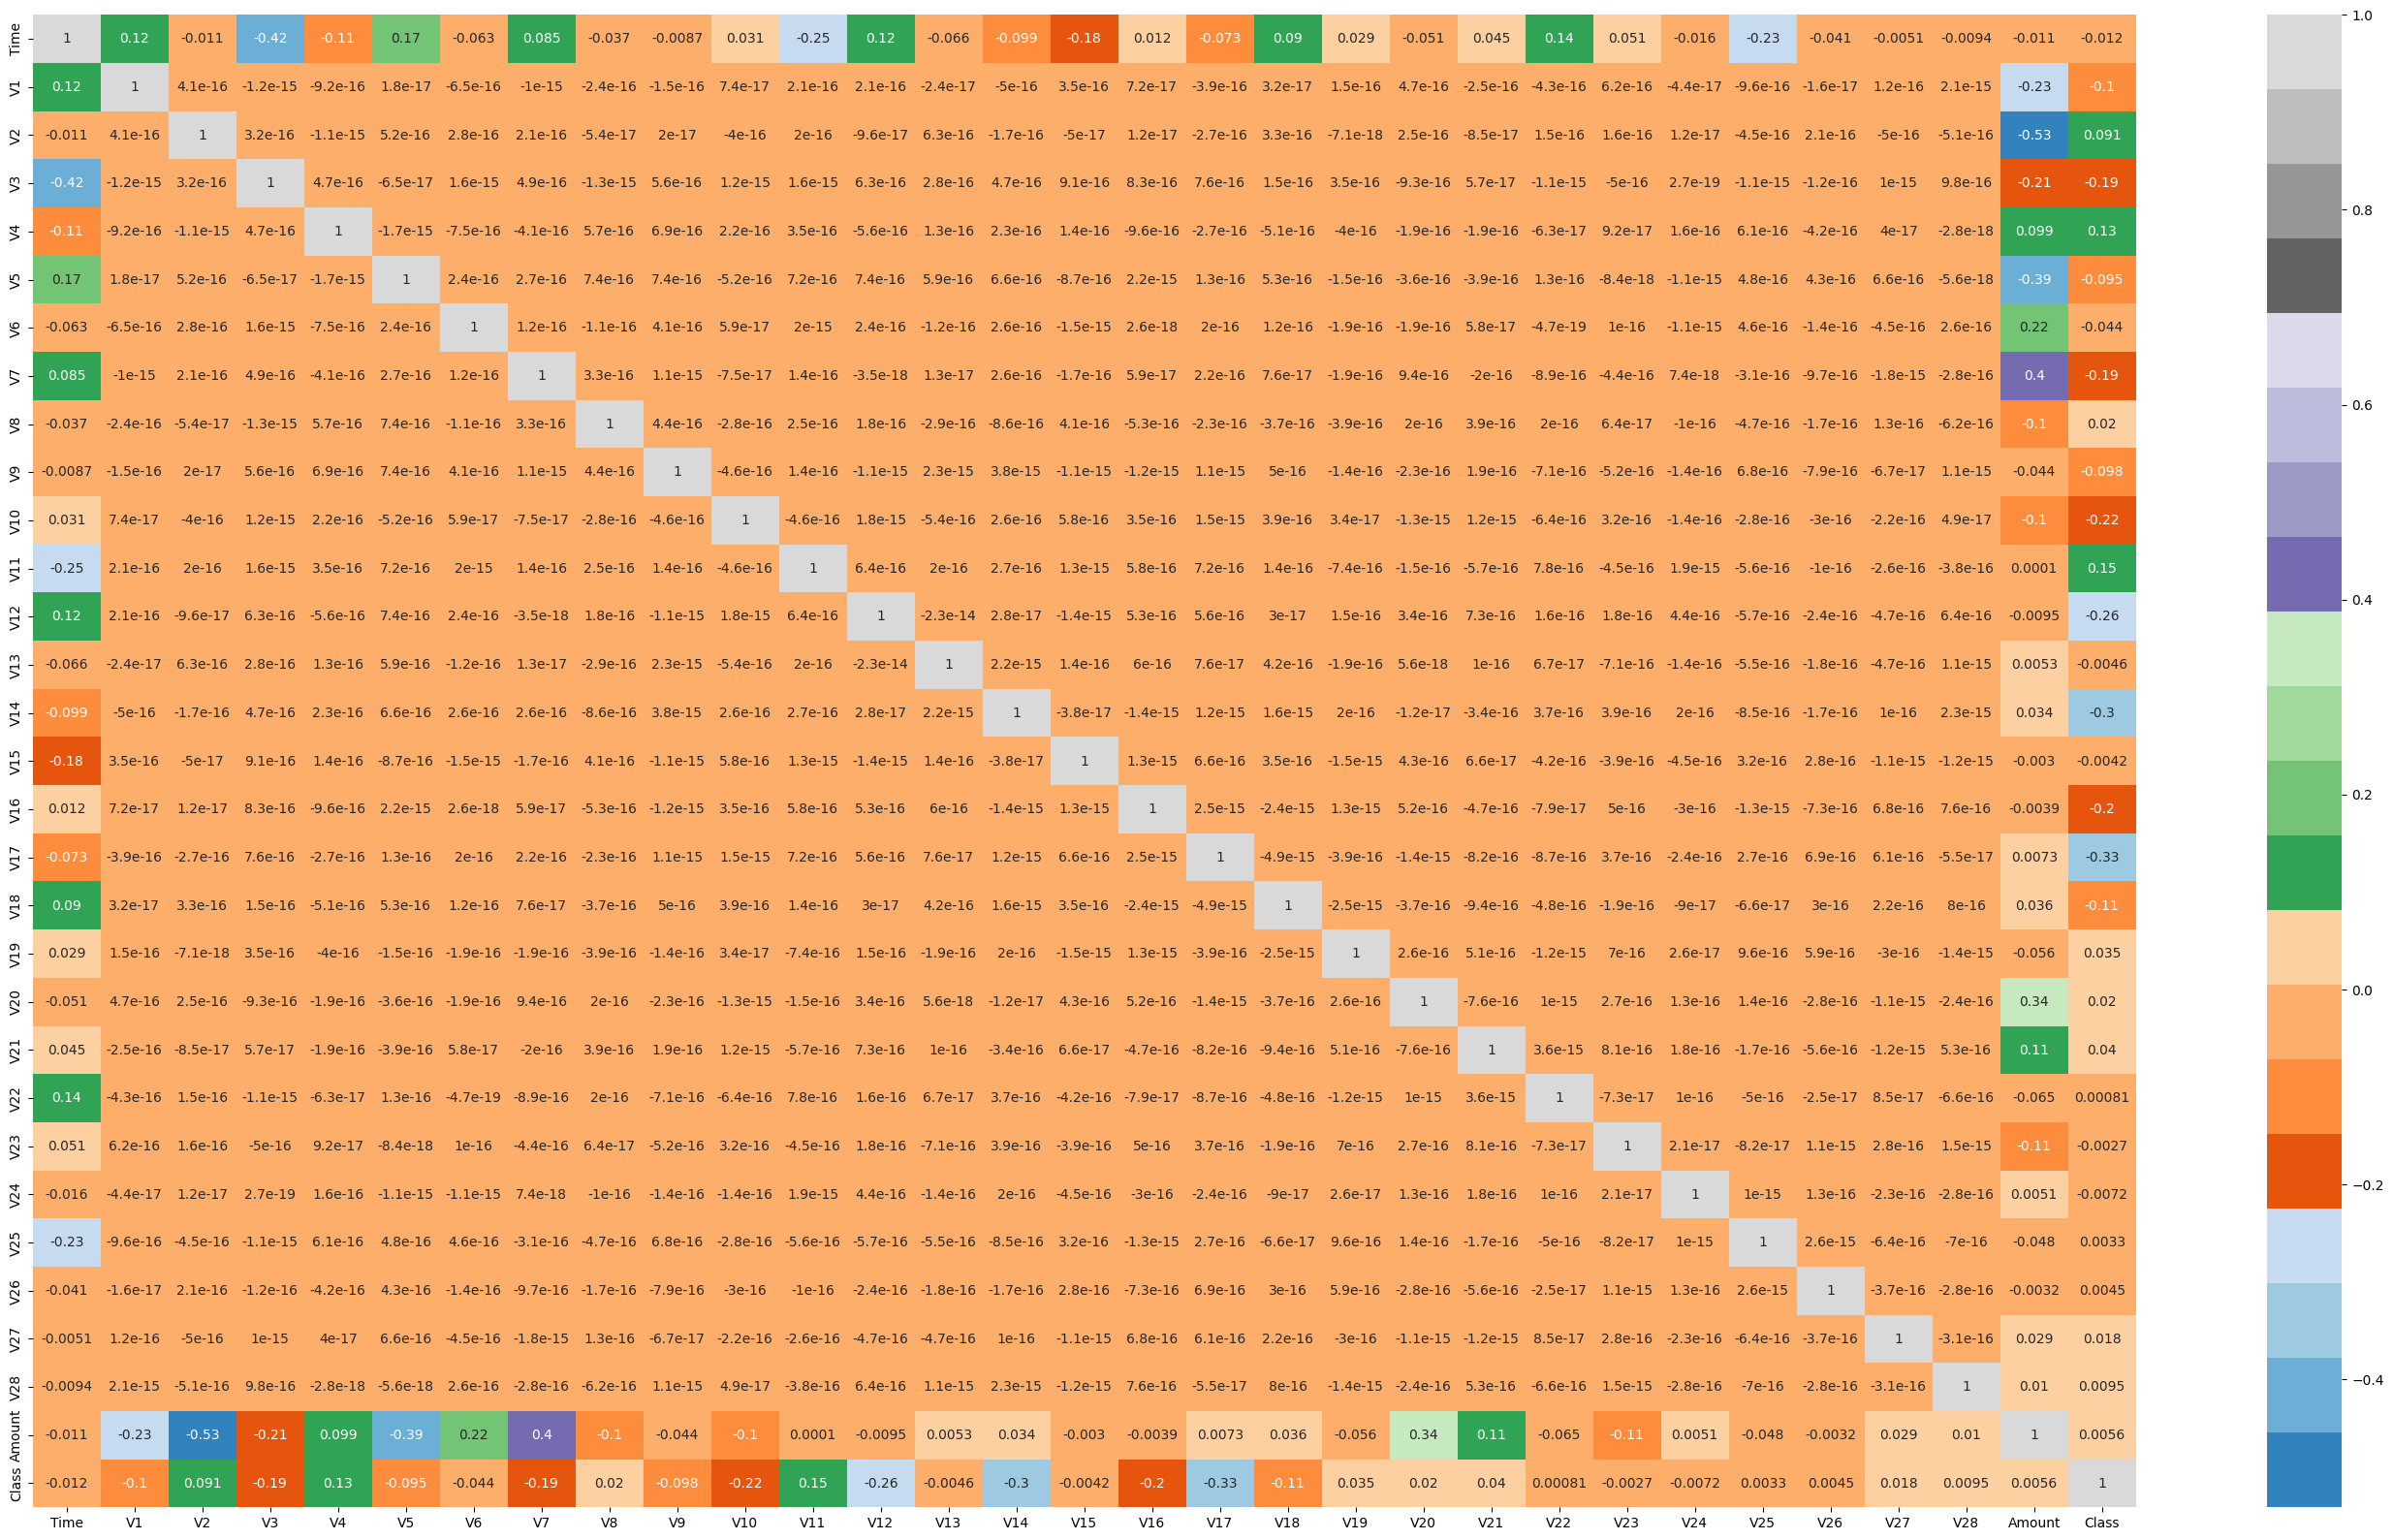

In [ ]:
plt.figure(figsize=(35,20))
sns.heatmap(df.corr(),annot=True,cmap="tab20c")

<Axes: xlabel='Class', ylabel='count'>

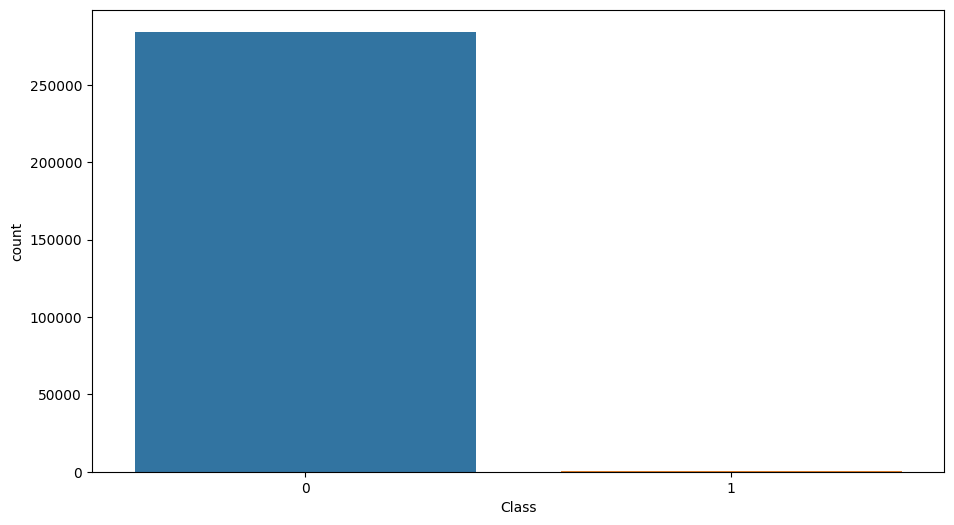

In [ ]:
#Plotting the count of Classes
fig=plt.figure(figsize=(11,6))
sns.countplot(x=df['Class'])

<ipython-input-7-1a94e3bfc93e>:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(temporary_data[col],ax=ax[index])
<ipython-input-7-1a94e3bfc93e>:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(temporary_data[col],ax=ax[index])
<ipython-input-7-1a94e3bfc93e>:7: UserWarning: 

`distplot` is a dep

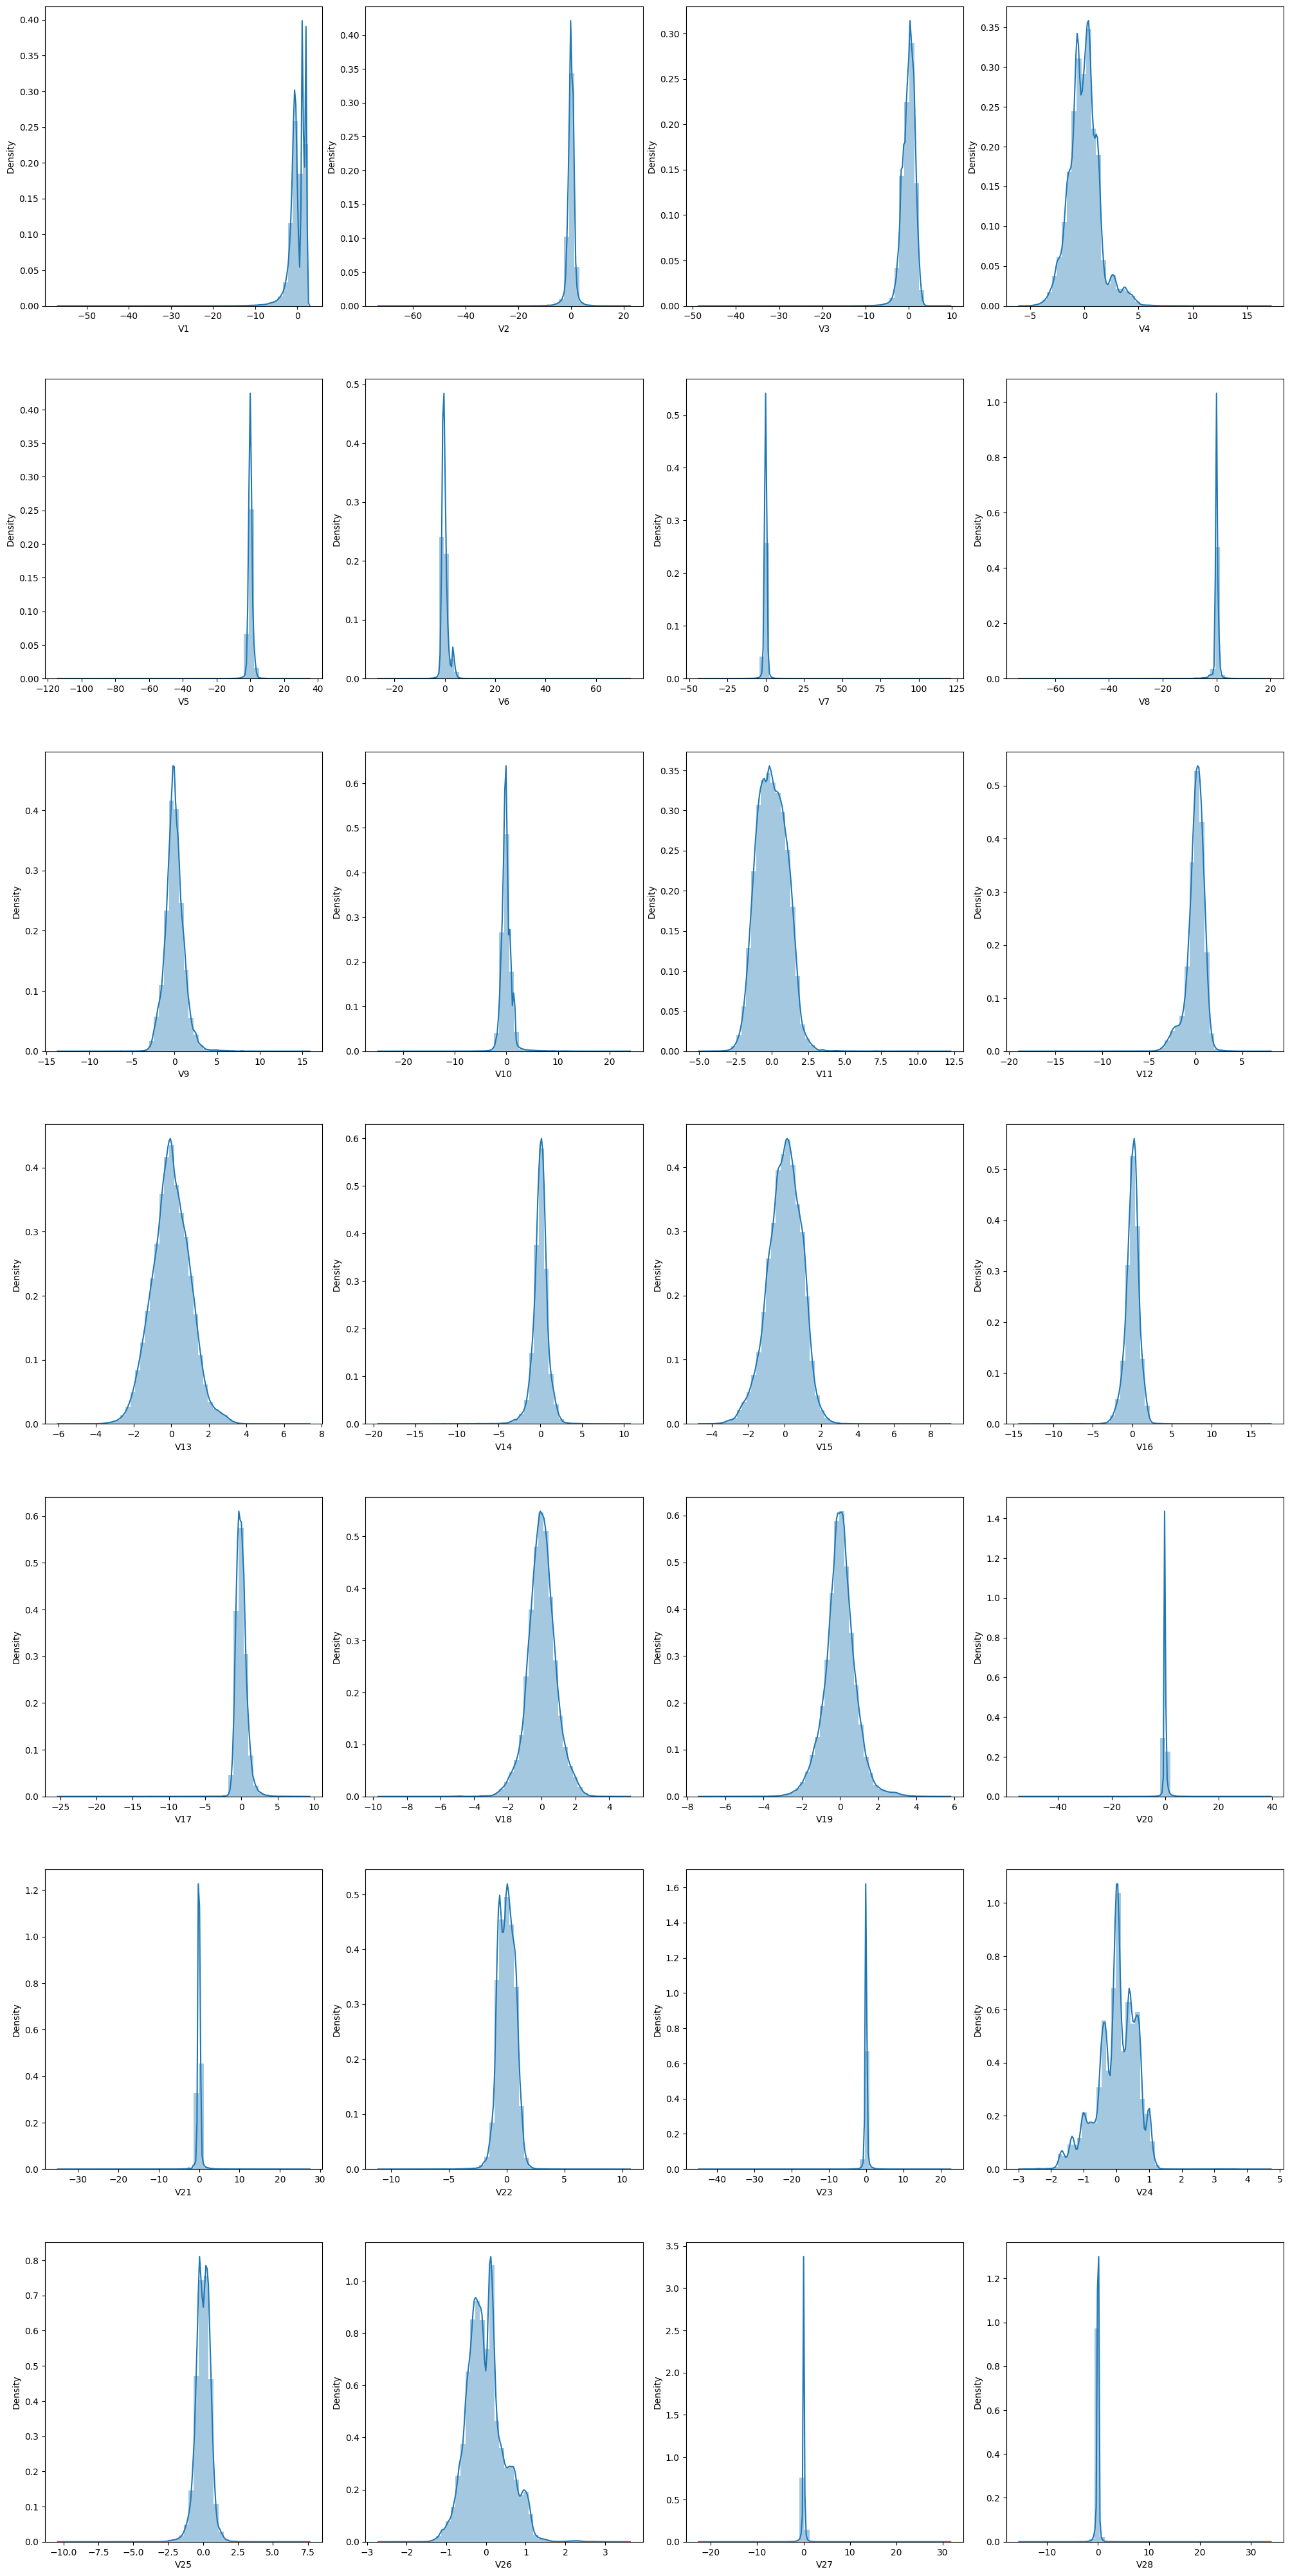

In [ ]:
temporary_df=df.drop(columns=['Time','Amount','Class'],axis=1)
#create dist plots
fig,ax=plt.subplots(ncols=4,nrows=7,figsize=(20,40))
index=0
ax=ax.flatten()
for col in temporary_df.columns:
  sns.distplot(temporary_df[col],ax=ax[index])
  index+=1
plt.tight_layout(pad=0.5,w_pad=0.5,h_pad=5)

<ipython-input-8-645911568fde>:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Time'])


<Axes: xlabel='Time', ylabel='Density'>

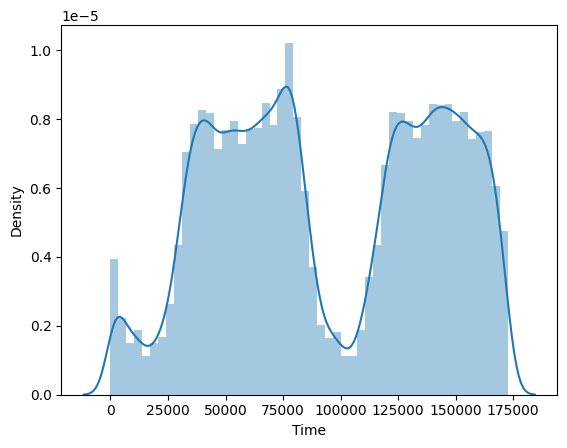

In [ ]:
sns.distplot(df['Time'])

<ipython-input-9-722483dc680a>:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Amount'])


<Axes: xlabel='Amount', ylabel='Density'>

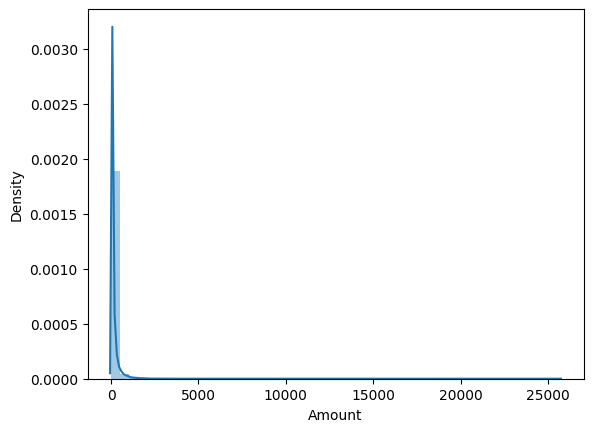

In [ ]:
sns.distplot(df['Amount'])

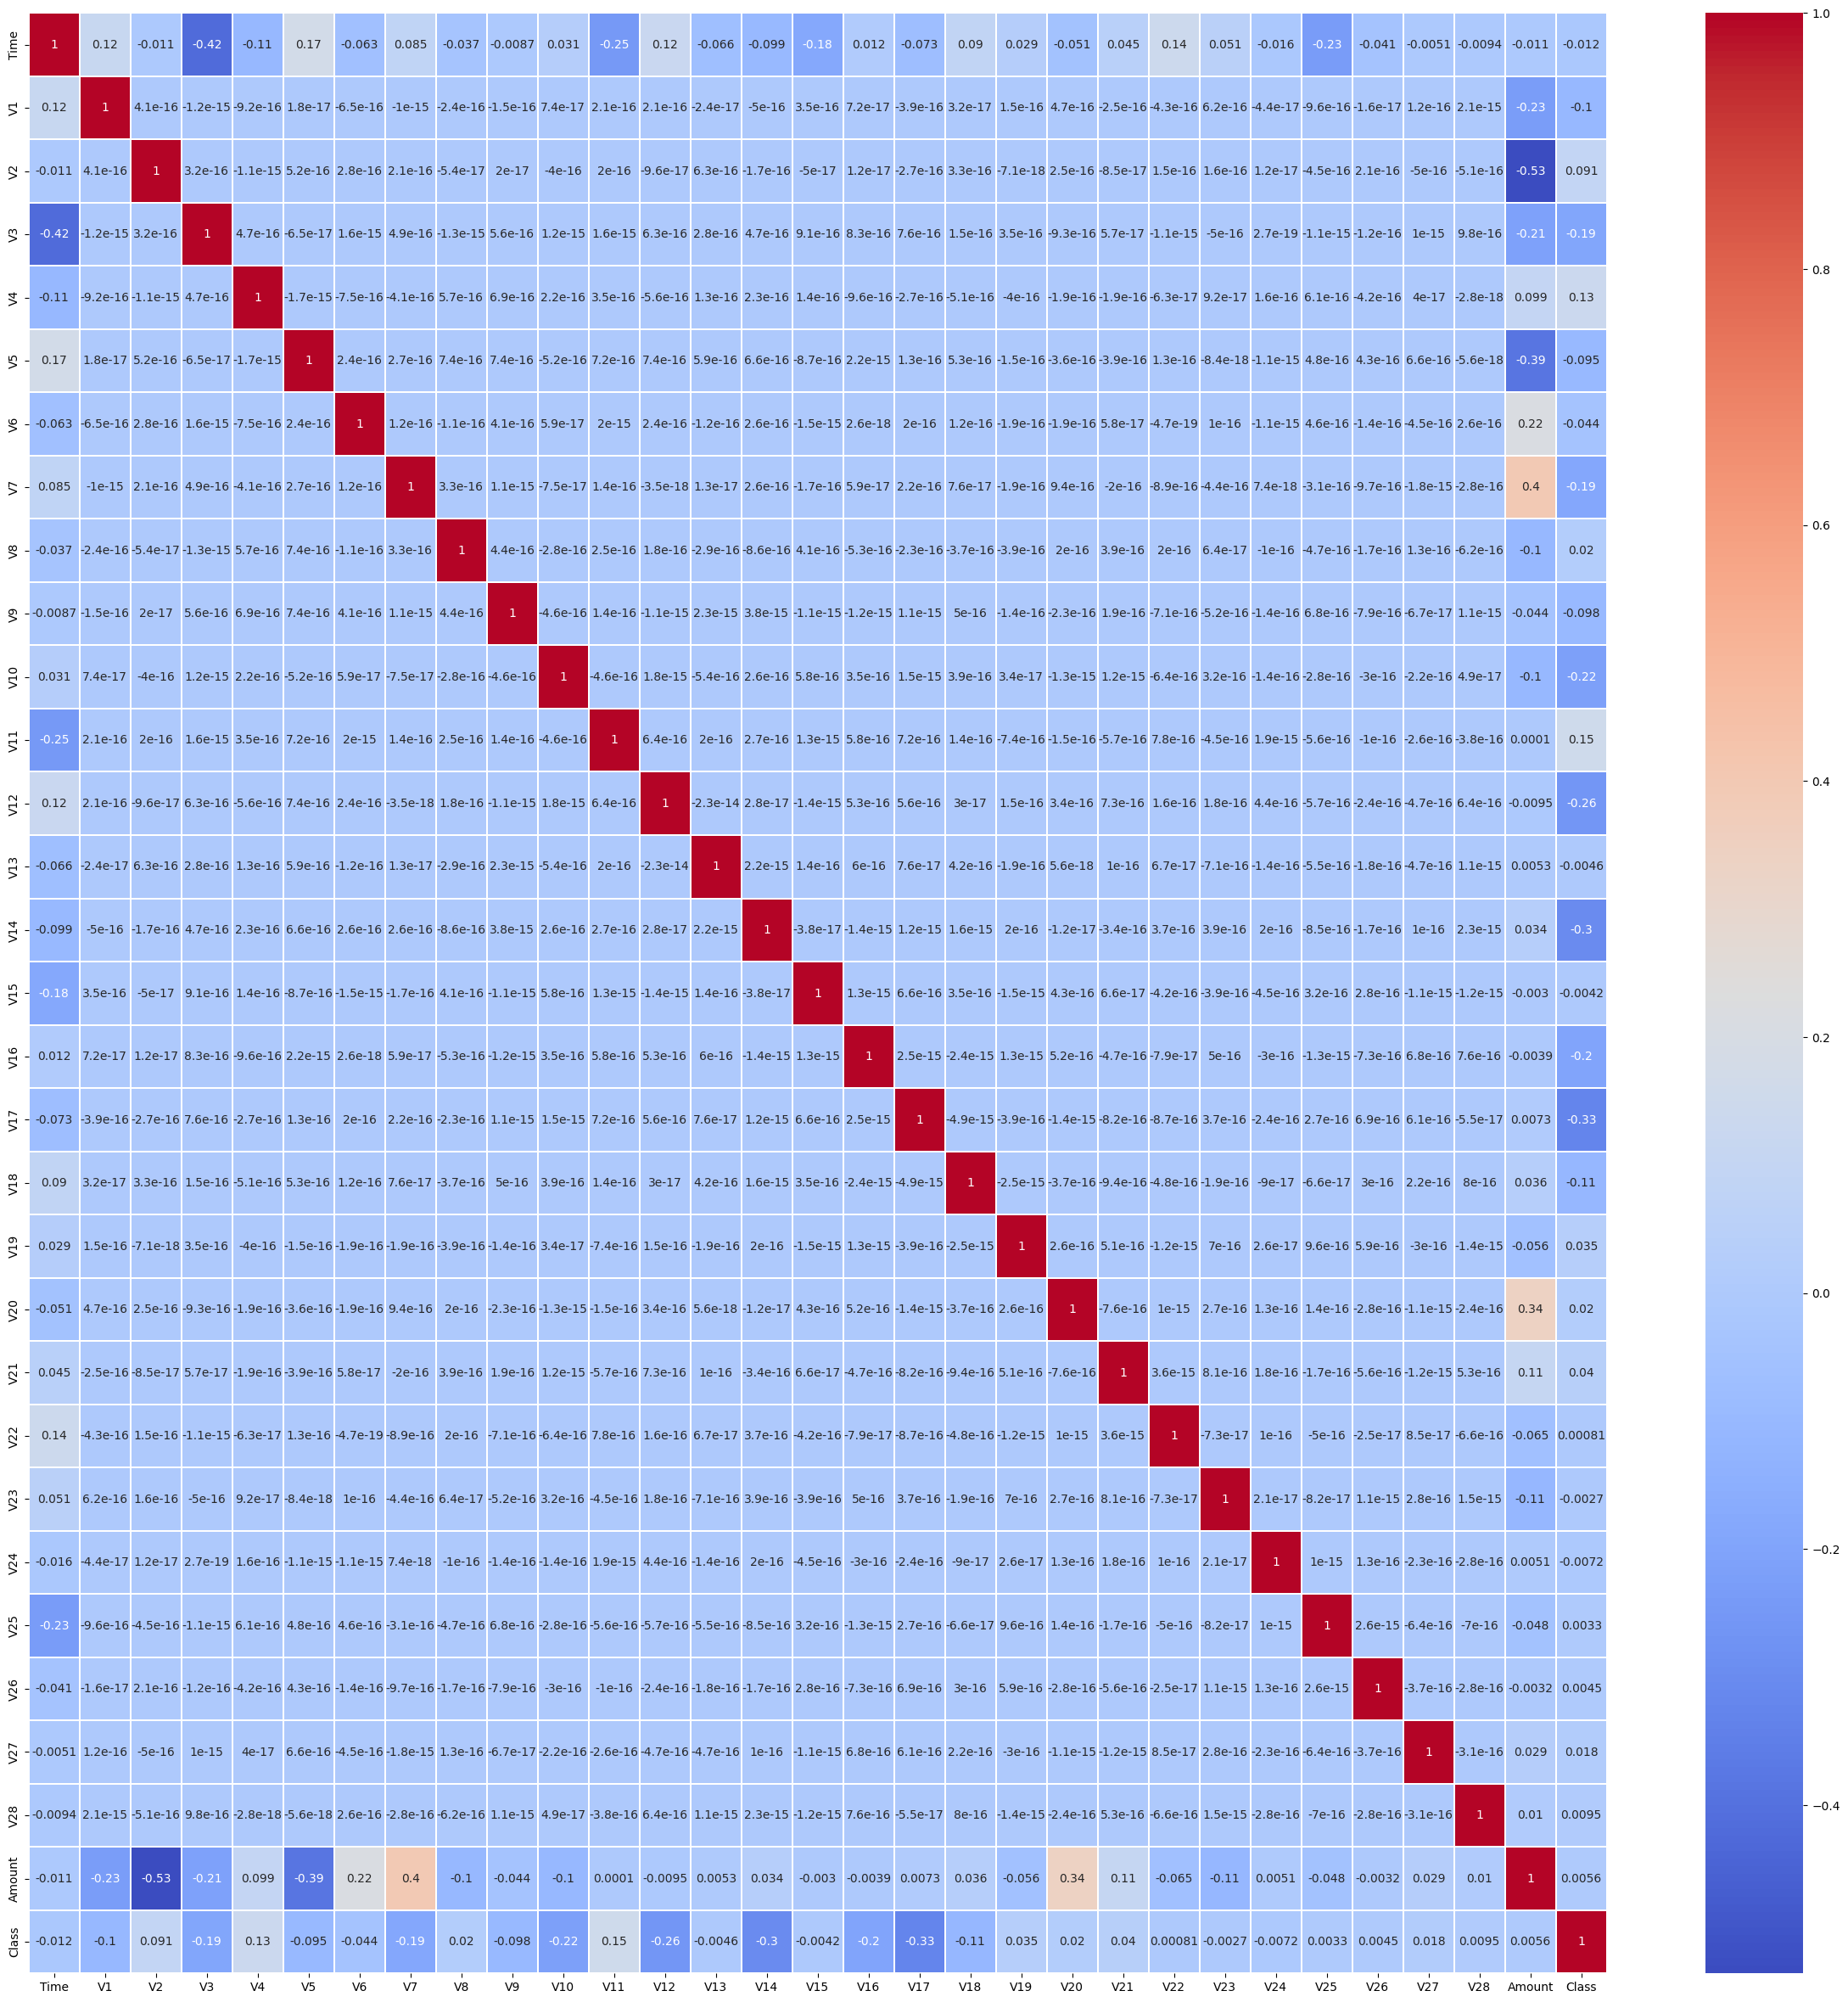

In [ ]:
names=df.columns
f, ax = plt.subplots(figsize=(30, 30))

#Correlation plot
df_corr = df.loc[:,names]
corr = df_corr.corr()

sns.heatmap(corr, annot = True, cmap='coolwarm',linewidths=.1)
plt.show()

In [ ]:
df['Class'].value_counts()

0    284315
1       492
Name: Class, dtype: int64

This Dataset is highly unblanced

0 --> Normal Transaction

1 --> fraudulent transaction

In [ ]:
df.shape

(284807, 31)

In [ ]:
original = df[df['Class'] == 0]
fraud = df[df['Class'] == 1]

In [ ]:
print("Shape of legit transactions data is :",original.shape)
print("Shape of fraud transactions data is :",fraud.shape)

Shape of legit transactions data is : (284315, 31)
Shape of fraud transactions data is : (492, 31)


In [ ]:
original.Amount.describe()

count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

In [ ]:
fraud.Amount.describe()

count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

In [ ]:
df.groupby('Class').mean()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
Class,,,,,,,,,,,,,,,,,,,,,
0,94838.202258,0.008258,-0.006271,0.012171,-0.007860,0.005453,0.002419,0.009637,-0.000987,0.004467,...,-0.000644,-0.001235,-0.000024,0.000070,0.000182,-0.000072,-0.000089,-0.000295,-0.000131,88.291022
1,80746.806911,-4.771948,3.623778,-7.033281,4.542029,-3.151225,-1.397737,-5.568731,0.570636,-2.581123,...,0.372319,0.713588,0.014049,-0.040308,-0.105130,0.041449,0.051648,0.170575,0.075667,122.211321


In [ ]:
print("fraud Transactions",df['Class'].value_counts()[1]/len(df['Class'])*100,"% of dataset")
print("Original Transactions",df['Class'].value_counts()[0]/len(df['Class'])*100,"% of dataset")
outlierFraction = len(fraud)/float(len(original))
print("Fraudulent transaction out all the transactions is :",outlierFraction*100,'%')

fraud Transactions 0.1727485630620034 % of dataset
Original Transactions 99.82725143693798 % of dataset
Fraudulent transaction out all the transactions is : 0.17304750013189596 %


# **Splitting the data into Features &** **Targets**

In [ ]:
X = df.drop(['Class'], axis=1)
Y = df['Class']

In [ ]:
# import plotly.express as px
# # Verifying transformation
# px.bar(Y.value_counts(), title='Fraudulent Charge Distrobution post-SMOTE')

**Train/test split before scaling**

In [ ]:
# Split first so the holdout set cannot influence preprocessing statistics.
X_train, X_test, y_train, y_test, scaler = prepare_train_test_data(
    X, Y, test_size=0.2, random_state=42
)


In [ ]:
print(Y)

In [ ]:
sns.scatterplot(x=X_train[:, 2], y=X_train[:, 3], hue=y_train)


In [ ]:
plt.hist(x=Y)

In [ ]:
X.shape

In [ ]:
X_train.shape

In [ ]:
X_test.shape

In [ ]:
print(pd.Series(y_train).value_counts())


**Model** **Training** **With Unbalanced Data**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,f1_score
from sklearn.metrics import accuracy_score
model = LogisticRegression()
# training the Logistic Regression Model with Training Data
model.fit(X_train, y_train)
#testing the Logistic Regression Model with Testing Data
y_prediction = model.predict(X_test)
print(classification_report(y_test, y_prediction))
print("F1_Score of LogisticRegression is :",f1_score(y_prediction,y_test))
print("Acuracy_Score of LogisticRegression is :",accuracy_score(y_prediction,y_test))

We observe that the accuracy value is so different from other evalution metrics,it is due to the unbalanced dataset.

# **Balancing** **The Dataset**

In [ ]:
# SMOTE is applied only to the scaled training partition in the next cell.


In [ ]:
X_train_resampled, y_train_resampled = resample_training_data(
    X_train, y_train, random_state=42
)


In [ ]:
print(X_train_resampled.shape, y_train_resampled.shape)


In [ ]:
import plotly.express as px

# This chart describes the resampled training partition, not the holdout set.
px.bar(
    pd.Series(y_train_resampled).value_counts(),
    title="Training class distribution after SMOTE",
)


# **Training The Models With Sampled** **Data**

**SELECTING THE DESIRED** **MODELS**

1.LogisticRegression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_recall_curve, auc
lr = LogisticRegression()
# training the Logistic Regression Model with Training Data
lr.fit(X_train_resampled, y_train_resampled)
#testing the Logistic Regression Model with Testing Data
y_prediction_lr = lr.predict(X_test)
precision_log, recall_log, _ = precision_recall_curve(y_test, y_prediction_lr)
auprc_log = auc(recall_log, precision_log)
print('AUPRC (LogisticRegression):', auprc_log)
print(classification_report(y_test, y_prediction_lr))
print("Confusion Matrix is :",confusion_matrix(y_test, y_prediction_lr))
print("F1_Score of LogisticRegression is :",f1_score(y_test,y_prediction_lr))
acc_lr=accuracy_score(y_prediction_lr,y_test)
print("Acuracy_Score of LogisticRegression is :",acc_lr)


2.XGBClassifier

In [ ]:
from xgboost import XGBClassifier
xgb = XGBClassifier(n_jobs=-1)
# training the RandomForestClassifier Model with Training Data
xgb.fit(X_train_resampled, y_train_resampled)
#testing the RandomForestClassifier Model with Testing Data
y_prediction_xgb = xgb.predict(X_test)
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, y_prediction_xgb)
auprc_xgb = auc(recall_xgb, precision_xgb)
print('AUPRC (XGBClassifier):', auprc_xgb)
print(classification_report(y_test, y_prediction_xgb))
print("Confusion Matrix is :",confusion_matrix(y_test, y_prediction_xgb))
acc_xgb=accuracy_score(y_prediction_xgb,y_test)
print("Acuracy_Score of XGBClassifier is :",acc_xgb)
print("F1 Score of XGBClassifier is :", f1_score (y_test,y_prediction_xgb))


3.KNeighborsClassifier

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Train and evaluate KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_resampled, y_train_resampled)
y_prediction_knn = knn.predict(X_test)
precision_knn, recall_knn, _ = precision_recall_curve(y_test, y_prediction_knn)
auprc_knn = auc(recall_knn, precision_knn)
print('AUPRC (KNN):', auprc_knn)
# Summary of the predictions made by the classifier
print(classification_report(y_test, y_prediction_knn))
print("Confusion Matrix is :",confusion_matrix(y_test, y_prediction_knn))
# Accuracy score
acc_knn=accuracy_score(y_prediction_knn,y_test)
print('Accuracy of KNeighborsClassifier is',acc_knn)

4.LinearDiscriminantAnalysis

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
# Linear Discriminant Analysis
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_resampled, y_train_resampled)
y_prediction_lda = lda.predict(X_test)
precision_lda, recall_lda, _ = precision_recall_curve(y_test, y_prediction_lda)
auprc_lda = auc(recall_lda, precision_lda)
print('AUPRC (LinearDiscriminantAnalysis):', auprc_lda)
# Summary of the predictions made by the classifier
print(classification_report(y_test, y_prediction_lda))
print("Confusion Matrix is :",confusion_matrix(y_test, y_prediction_lda))
# Accuracy score
acc_lda=accuracy_score(y_prediction_lda,y_test)
print('Accuracy of LinearDiscriminantAnalysis is',acc_lda)
print("F1 Score of LinearDiscriminantAnalysis is :", f1_score (y_test,y_prediction_lda))

5.Super Vector Machine

In [ ]:
from sklearn.svm import SVC
svc = SVC()
svc.fit(X_train_resampled, y_train_resampled)
y_prediction_svc = svc.predict(X_test)
precision_svc, recall_svc, _ = precision_recall_curve(y_test, y_prediction_svc)
auprc_svc = auc(recall_svc, precision_svc)
print('AUPRC (SVC):', auprc_svc)
# Summary of the predictions made by the classifier
print(classification_report(y_test, y_prediction_svc))
print(confusion_matrix(y_test, y_prediction_svc))
# Accuracy score
acc_svc=accuracy_score(y_prediction_svc,y_test)
print('Accuracy of Super Vector Machine is',acc_svc)

6.KMeans

In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2)
kmeans.fit(X_train_resampled, y_train_resampled)
test_pred_km = kmeans.predict(X_test)
acc_km=accuracy_score(y_test,test_pred_km)
precision_km, recall_km, _ = precision_recall_curve(y_test, test_pred_km)
auprc_km = auc(recall_km, precision_km)
print('AUPRC (KMeans):', auprc_km)
# Summary of the predictions made by the classifier
print(classification_report(y_test, test_pred_km))
# Accuracy score
print('Accuracy of KMeans is',acc_km)


7.RandomForestClassifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rand = RandomForestClassifier()
# training the RandomForestClassifier Model with Training Data
rand.fit(X_train_resampled, y_train_resampled)
#testing the RandomForestClassifier Model with Testing Data
y_prediction_rand = rand.predict(X_test)
precision_rand, recall_rand, _ = precision_recall_curve(y_test, y_prediction_rand)
auprc_rand = auc(recall_rand, precision_rand)
print('AUPRC (RandomForestClassifier):', auprc_rand)
print(classification_report(y_test, y_prediction_rand))
print("Confusion Matrix is :",confusion_matrix(y_test, y_prediction_rand))
print("F1_Score of RandomForestClassifier is :",f1_score(y_prediction_rand,y_test))
acc_rand=accuracy_score(y_prediction_rand,y_test)
print("Acuracy_Score of RandomForestClassifier is :",acc_rand)


# **Comparision**

In [ ]:
Models=pd.DataFrame({'Models':['XGBClassifier','KNeighbors','Logistic Regression','LinearDiscriminantAnalysis','K-means','Random forest regressor',' Support Vector Machine'],
                     'accuracy_Score':[acc_xgb,acc_knn,acc_lr,acc_lda,acc_km,acc_rand,acc_svc]
                    })
Models

In [ ]:
fig=plt.figure(figsize=(5,5))
sns.barplot(x=Models.Models,y=Models.accuracy_Score)
plt.xticks(rotation=90)
fig.show()

# **ROC** **Plots**

In [ ]:
from sklearn.metrics import roc_auc_score,roc_curve

KNN

In [ ]:
r_fpr,r_tpr,_=roc_curve(y_test,y_prediction_knn)
r_auc=roc_auc_score(y_test,y_prediction_knn)
plt.plot(r_fpr,r_tpr,label='KNeighbors (area={:.3f})'.format(r_auc))
plt.title('ROC plot KNeighbors')
plt.xlabel('False Positive rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
plt.show()

RandomForestClassifier

In [ ]:
r_fpr,r_tpr,_=roc_curve(y_test,y_prediction_rand)
r_auc=roc_auc_score(y_test,y_prediction_rand)
plt.plot(r_fpr,r_tpr,label='RandomForest (area={:.3f})'.format(r_auc))
plt.title('ROC plot RandomForestClassifier')
plt.xlabel('False Positive rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
plt.show()

SVC

In [ ]:
r_fpr,r_tpr,_=roc_curve(y_test,y_prediction_svc)
r_auc=roc_auc_score(y_test,y_prediction_svc)
plt.plot(r_fpr,r_tpr,label='SuperVectorMachine (area={:.3f})'.format(r_auc))
plt.title('ROC plot SVC')
plt.xlabel('False Positive rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
plt.show()

Kmeans

In [ ]:
r_fpr,r_tpr,_=roc_curve(y_test,test_pred_km)
r_auc=roc_auc_score(y_test,test_pred_km)
plt.plot(r_fpr,r_tpr,label='Kmeans (area={:.3f})'.format(r_auc))
plt.title('ROC plot Kmeans')
plt.xlabel('False Positive rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
plt.show()

LinearDiscriminantAnalysis

In [ ]:
r_fpr,r_tpr,_=roc_curve(y_test,y_prediction_lda)
r_auc=roc_auc_score(y_test,y_prediction_lda)
plt.plot(r_fpr,r_tpr,label='LinearDiscriminantAnalysis (area={:.3f})'.format(r_auc))
plt.title('ROC plot LDA')
plt.xlabel('False Positive rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
plt.show()

XGBClassifier

In [ ]:
r_fpr,r_tpr,_=roc_curve(y_test,y_prediction_xgb)
r_auc=roc_auc_score(y_test,y_prediction_xgb)
plt.plot(r_fpr,r_tpr,label='XGBClassifier (area={:.3f})'.format(r_auc))
plt.title('ROC plot XGBClassifier')
plt.xlabel('False Positive rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
plt.show()

LogisticRegression

In [ ]:
r_fpr,r_tpr,_=roc_curve(y_test,y_prediction_lr)
r_auc=roc_auc_score(y_test,y_prediction_lr)
plt.plot(r_fpr,r_tpr,label='LogisticRegression (area={:.3f})'.format(r_auc))
plt.title('ROC plot LogisticRegressionr')
plt.xlabel('False Positive rate')
plt.ylabel('True Positive rate')
plt.legend(loc='best')
plt.show()